<a href="https://colab.research.google.com/github/caniletgo/ML/blob/main/%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_%D0%A7%D0%B5%D1%80%D0%BD%D0%B8%D1%88_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Завантаження даних та первинний аналіз (EDA)

Розмір датасету: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Інформація про типи даних та пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pa

/tmp/ipykernel_8146/1182576221.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', ax=axes[0], palette='pastel')


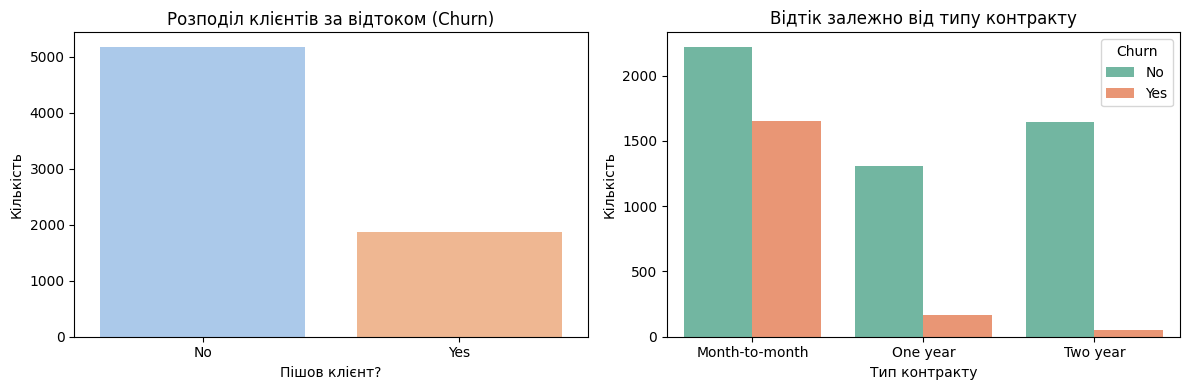

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Завантажуємо датасет Telco Customer Churn
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Розмір датасету:", df.shape)
display(df.head())

print("\nІнформація про типи даних та пропуски:")
print(df.info())

print("\nРозподіл цільової змінної Churn (відтік):")
print(df['Churn'].value_counts(normalize=True).round(3) * 100)

# Візуалізація розподілу відтоку та залежності від типу контракту
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x='Churn', ax=axes[0], palette='pastel')
axes[0].set_title('Розподіл клієнтів за відтоком (Churn)')
axes[0].set_xlabel('Пішов клієнт?')
axes[0].set_ylabel('Кількість')

sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[1], palette='Set2')
axes[1].set_title('Відтік залежно від типу контракту')
axes[1].set_xlabel('Тип контракту')
axes[1].set_ylabel('Кількість')

plt.tight_layout()
plt.show()

2. Підготовка даних (Preprocessing)

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Видаляємо ID клієнта, оскільки він не впливає на прогноз
df_clean = df.drop(columns=['customerID']).copy()

# 2. Колонка TotalCharges завантажилась як текст через пробіли у нових клієнтів — переводимо у числа
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(df_clean['TotalCharges'].median())

# 3. Перетворюємо цільову змінну Churn у 0 та 1
df_clean['Churn'] = df_clean['Churn'].map({'No': 0, 'Yes': 1})

# 4. Розділяємо на ознаки (X) та ціль (y)
X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn']

numeric_features = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [col for col in X.columns if col not in numeric_features]

# 5. Розбиваємо на навчальну (80%) та тестову (20%) вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Створюємо конвеєр обробки: масштабування чисел + One-Hot кодування категорій
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (5634, 19)
Тестова вибірка: (1409, 19)


3. Навчання моделей, підбір гіперпараметрів та порівняння

Найкращі параметри Random Forest: {'model__max_depth': 6, 'model__n_estimators': 200}

Порівняльна таблиця результатів:


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
1,Random Forest (Tuned),0.8013,0.6780,0.4786,0.5611,0.8421
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
2,Gradient Boosting,0.8027,0.6644,0.5187,0.5826,0.8412



Обрана найкраща модель: Random Forest (Tuned)


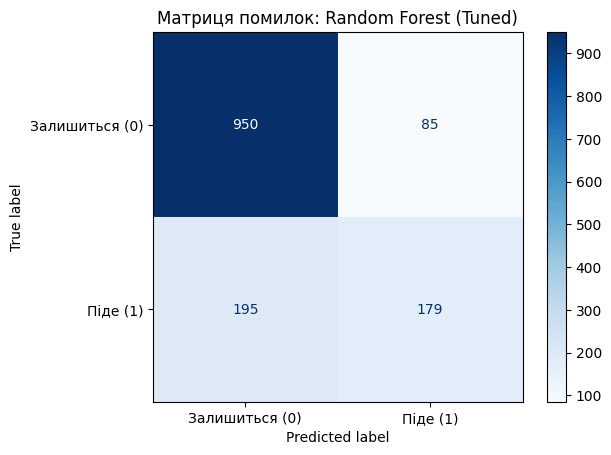

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# Модель 1: Логістична регресія
pipe_lr = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_lr.fit(X_train, y_train)

# Модель 2: Випадковий ліс із підбором параметрів (GridSearchCV)
pipe_rf = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])
param_grid_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [6, 10, None]
}
grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=3, scoring='roc_auc', n_jobs=-1)
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_
print("Найкращі параметри Random Forest:", grid_rf.best_params_)

# Модель 3: Градієнтний бустинг
pipe_gb = Pipeline([
    ('prep', preprocessor),
    ('model', GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42))
])
pipe_gb.fit(X_train, y_train)

# Оцінюємо всі три моделі на тестовій вибірці
models = {
    'Logistic Regression': pipe_lr,
    'Random Forest (Tuned)': best_rf,
    'Gradient Boosting': pipe_gb
}

results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({
        'Модель': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    })

results_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
print("\nПорівняльна таблиця результатів:")
display(results_df)

# Автоматично обираємо найкращу модель за ROC-AUC
best_model_name = results_df.iloc[0]['Модель']
best_model = models[best_model_name]
print(f"\nОбрана найкраща модель: {best_model_name}")

# Матриця помилок для найкращої моделі
cm = confusion_matrix(y_test, best_model.predict(X_test))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Залишиться (0)', 'Піде (1)'])
disp.plot(cmap='Blues')
plt.title(f'Матриця помилок: {best_model_name}')
plt.show()

4. Прогноз для клієнта (введення даних і результат)

In [4]:
print("Введіть дані клієнта (або натисніть Enter для прикладу):")

tenure_in = int(input("Термін користування послугами в місяцях (напр. 2): ") or 2)
monthly_in = float(input("Щомісячний платіж, $ (напр. 89.5): ") or 89.5)
total_in = float(input("Загальна сума платежів, $ (напр. 179.0): ") or 179.0)
contract_in = input("Тип контракту (Month-to-month / One year / Two year) [Month-to-month]: ") or "Month-to-month"
internet_in = input("Інтернет (DSL / Fiber optic / No) [Fiber optic]: ") or "Fiber optic"
tech_in = input("Техпідтримка (Yes / No / No internet service) [No]: ") or "No"
payment_in = input("Оплата (Electronic check / Mailed check / Bank transfer (automatic) / Credit card (automatic)) [Electronic check]: ") or "Electronic check"

# Формуємо профіль клієнта
new_client = pd.DataFrame([{
    'gender': 'Female',
    'SeniorCitizen': 0,
    'Partner': 'No',
    'Dependents': 'No',
    'tenure': tenure_in,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': internet_in,
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': tech_in,
    'StreamingTV': 'Yes',
    'StreamingMovies': 'Yes',
    'Contract': contract_in,
    'PaperlessBilling': 'Yes',
    'PaymentMethod': payment_in,
    'MonthlyCharges': monthly_in,
    'TotalCharges': total_in
}])

prediction = best_model.predict(new_client)[0]
probability = best_model.predict_proba(new_client)[0][1]

print("\n--- РЕЗУЛЬТАТ ПРОГНОЗУ ---")
print(f"Ймовірність відтоку клієнта: {probability * 100:.1f}%")
if prediction == 1:
    print("Висновок моделі: КЛІЄНТ ПІДЕ (високий ризик відтоку).")
else:
    print("Висновок моделі: КЛІЄНТ ЗАЛИШИТЬСЯ.")

Введіть дані клієнта (або натисніть Enter для прикладу):
Термін користування послугами в місяцях (напр. 2): 
Щомісячний платіж, $ (напр. 89.5): 
Загальна сума платежів, $ (напр. 179.0): 
Тип контракту (Month-to-month / One year / Two year) [Month-to-month]: 
Інтернет (DSL / Fiber optic / No) [Fiber optic]: 
Техпідтримка (Yes / No / No internet service) [No]: 
Оплата (Electronic check / Mailed check / Bank transfer (automatic) / Credit card (automatic)) [Electronic check]: 

--- РЕЗУЛЬТАТ ПРОГНОЗУ ---
Ймовірність відтоку клієнта: 72.3%
Висновок моделі: КЛІЄНТ ПІДЕ (високий ризик відтоку).


Висновок

У цій роботі я проаналізувала дані про 7043 клієнтів телеком-компанії та підготувала їх до навчання, прибравши зайвий ідентифікатор і перевівши текстові значення в числа. Далі я навчила й порівняла три моделі, серед яких найкращий результат за показником ROC-AUC (0,8421) після підбору параметрів показав випадковий ліс із точністю 80,13%. За матрицею помилок модель правильно вгадала 950 лояльних клієнтів і 179 тих, хто пішов, але частину відтоку все ж пропустила, бо таких прикладів у базі менше. Під час тестування на даних одного клієнта з помісячним контрактом програма спрогнозувала ймовірність 72,3%, що він відмовиться від послуг. Отже, модель працює добре і допомагає заздалегідь побачити клієнтів, які можуть піти, щоб вчасно запропонувати їм кращі умови.